In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import glob

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:
# Load dataset

df = pd.read_csv(
    '/content/data.csv',
    encoding='ISO-8859-1'
)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [11]:
# ==========================================
# STEP 2: LOAD DATASET
# ==========================================

file_path = '/content/data.csv'

df = pd.read_csv(file_path, encoding='ISO-8859-1')

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (125339, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [12]:
# Check column names
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [13]:
# Statistical summary
df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,125339,125339,124994,125338.000000,125338,125338.000000,84465.00000,125338
unique,5988,3226,3153,NaN,5433,NaN,NaN,32
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,12/6/2010 16:57,NaN,NaN,United Kingdom
freq,675,673,683,NaN,675,NaN,NaN,115440
mean,NaN,NaN,NaN,8.923032,NaN,5.299422,15309.01738,NaN
std,NaN,NaN,NaN,301.800019,NaN,111.195412,1741.71487,NaN
min,NaN,NaN,NaN,-74215.000000,NaN,0.000000,12346.00000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13894.00000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.460000,15235.00000,NaN
75%,NaN,NaN,NaN,9.000000,NaN,4.240000,16904.00000,NaN


In [14]:
print("First 5 records:")
display(df.head())

print("Last 5 records:")
display(df.tail())

First 5 records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom


Last 5 records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
125334,547042,82613B,"METAL SIGN,CUPCAKE SINGLE HOOK",1.0,3/20/2011 11:00,2.46,NaN,United Kingdom
125335,547042,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,1.0,3/20/2011 11:00,7.46,NaN,United Kingdom
125336,547042,84279P,CHERRY BLOSSOM DECORATIVE FLASK,1.0,3/20/2011 11:00,8.29,NaN,United Kingdom
125337,547042,84380,SET OF 3 BUTTERFLY COOKIE CUTTERS,1.0,3/20/2011 11:00,2.46,NaN,United Kingdom
125338,547042,84406B,CREAM CUPID HEARTS COAT HA,NaN,NaN,NaN,NaN,NaN


In [15]:
rows, columns = df.shape

print("Total Rows:", rows)
print("Total Columns:", columns)

Total Rows: 125339
Total Columns: 8


In [16]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


,0
InvoiceNo,0
StockCode,0
Description,345
Quantity,1
InvoiceDate,1
UnitPrice,1
CustomerID,40874
Country,1


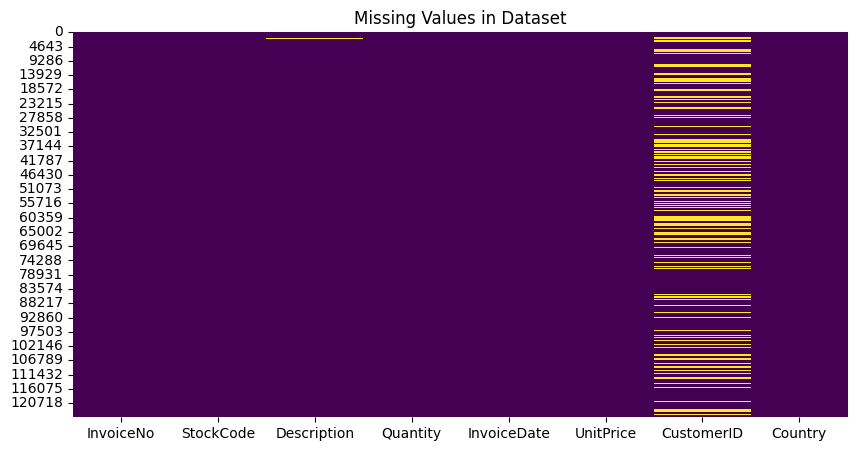

In [17]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap='viridis')

plt.title("Missing Values in Dataset")
plt.show()

In [18]:

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 1114


In [19]:
df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,125338.000000,125338.000000
mean,8.923032,5.299422
std,301.800019,111.195412
min,-74215.000000,0.000000
25%,1.000000,1.250000
50%,3.000000,2.460000
75%,9.000000,4.240000
max,74215.000000,16888.020000


In [20]:
print("Unique Customers:", df['CustomerID'].nunique())
print("Unique Products:", df['StockCode'].nunique())
print("Unique Countries:", df['Country'].nunique())
print("Unique Invoices:", df['InvoiceNo'].nunique())

Unique Customers: 2017
Unique Products: 3226
Unique Countries: 32
Unique Invoices: 5988


In [21]:
# Create a copy of original dataset
df_clean = df.copy()

print("Working copy created.")

Working copy created.


In [22]:
df_clean.columns = df_clean.columns.str.strip()

print(df_clean.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [23]:
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates()

after_duplicates = len(df_clean)

print("Records before removing duplicates:", before_duplicates)
print("Records after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Records before removing duplicates: 125339
Records after removing duplicates: 124225
Duplicates removed: 1114


In [24]:
print("Missing values before handling:")
display(df_clean.isnull().sum())

Missing values before handling:


,0
InvoiceNo,0
StockCode,0
Description,345
Quantity,1
InvoiceDate,1
UnitPrice,1
CustomerID,40862
Country,1


In [25]:
# Remove missing StockCode
df_clean = df_clean.dropna(subset=['StockCode'])

# Fill missing descriptions
df_clean['Description'] = df_clean['Description'].fillna('Unknown Product')

# Fill missing country
df_clean['Country'] = df_clean['Country'].fillna('Unknown Country')

print("Missing values handled.")

Missing values handled.


In [26]:
# CustomerID can contain missing values, so use nullable integer
df_clean['CustomerID'] = pd.to_numeric(
    df_clean['CustomerID'], errors='coerce'
).astype('Int64')

# Quantity
df_clean['Quantity'] = pd.to_numeric(
    df_clean['Quantity'], errors='coerce'
)

# Unit price
df_clean['UnitPrice'] = pd.to_numeric(
    df_clean['UnitPrice'], errors='coerce'
)

# Invoice date
df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'], errors='coerce'
)

print(df_clean.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity              float64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object


In [27]:
df_clean = df_clean.dropna(subset=['InvoiceDate'])

print("Invalid dates removed.")

Invalid dates removed.


In [28]:
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)

df_clean['IsCancelled'] = df_clean['InvoiceNo'].str.startswith('C')

print("Cancelled transactions:", df_clean['IsCancelled'].sum())
print("Normal transactions:", (~df_clean['IsCancelled']).sum())

Cancelled transactions: 2280
Normal transactions: 121944


In [29]:
df_sales = df_clean[
    (df_clean['IsCancelled'] == False) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

print("Sales dataset created.")
print("Original records:", len(df_clean))
print("Valid sales records:", len(df_sales))

Sales dataset created.
Original records: 124224
Valid sales records: 121301


In [30]:
# Outlier detection in UnitPrice

Q1 = df_sales['UnitPrice'].quantile(0.25)
Q3 = df_sales['UnitPrice'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_sales['PriceOutlier'] = (
    (df_sales['UnitPrice'] < lower_bound) |
    (df_sales['UnitPrice'] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Price outliers detected:", df_sales['PriceOutlier'].sum())

Q1: 1.25
Q3: 4.21
IQR: 2.96
Lower Bound: -3.1899999999999995
Upper Bound: 8.649999999999999
Price outliers detected: 8162


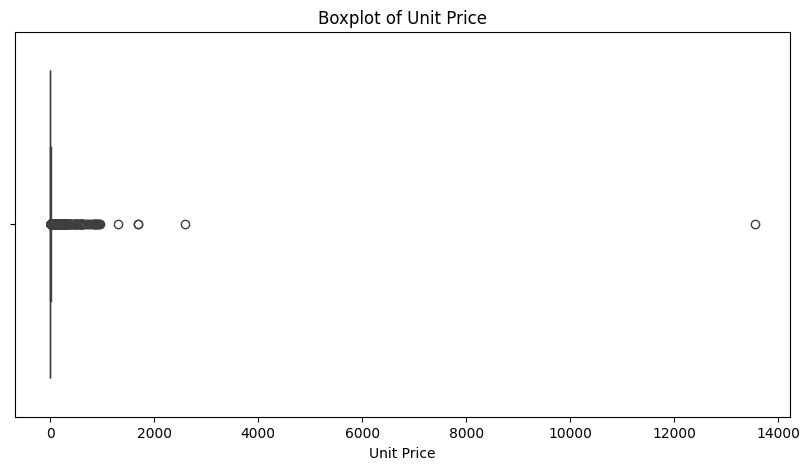

In [31]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_sales['UnitPrice'])

plt.title("Boxplot of Unit Price")
plt.xlabel("Unit Price")
plt.show()

In [32]:
customer_data = df_sales[
    ['CustomerID', 'Country']
].drop_duplicates()

customer_data = customer_data.dropna(subset=['CustomerID'])

customer_data.head()

,CustomerID,Country
0,17850,United Kingdom
9,13047,United Kingdom
26,12583,France
46,13748,United Kingdom
65,15100,United Kingdom


In [33]:
product_data = df_sales[
    ['StockCode', 'Description', 'UnitPrice']
].drop_duplicates(subset=['StockCode'])

product_data.head()

,StockCode,Description,UnitPrice
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55
1,71053,WHITE METAL LANTERN,3.39
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39


In [34]:
product_data = df_sales[
    ['StockCode', 'Description', 'UnitPrice']
].drop_duplicates(subset=['StockCode'])

product_data.head()

,StockCode,Description,UnitPrice
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55
1,71053,WHITE METAL LANTERN,3.39
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39


In [35]:
integrated_data = pd.merge(
    df_sales,
    customer_data,
    on='CustomerID',
    how='left',
    suffixes=('', '_Customer')
)

print("Integrated dataset created.")
display(integrated_data.head())

Integrated dataset created.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,PriceOutlier,Country_Customer
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,False,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,False,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,United Kingdom


In [36]:
print("Sales dataset rows:", len(df_sales))
print("Integrated dataset rows:", len(integrated_data))

print("Missing customer IDs:", integrated_data['CustomerID'].isnull().sum())

Sales dataset rows: 121301
Integrated dataset rows: 121529
Missing customer IDs: 40114


In [38]:
# Calculate total sales amount for each transaction

df_sales['TotalAmount'] = (
    df_sales['Quantity'] * df_sales['UnitPrice']
)

print("Total sales amount calculated successfully!")

display(
    df_sales[
        ['InvoiceNo', 'StockCode', 'Quantity',
         'UnitPrice', 'TotalAmount']
    ].head(10)
)

Total sales amount calculated successfully!


,InvoiceNo,StockCode,Quantity,UnitPrice,TotalAmount
0,536365,85123A,6.0,2.55,15.30
1,536365,71053,6.0,3.39,20.34
2,536365,84406B,8.0,2.75,22.00
3,536365,84029G,6.0,3.39,20.34
4,536365,84029E,6.0,3.39,20.34
5,536365,22752,2.0,7.65,15.30
6,536365,21730,6.0,4.25,25.50
7,536366,22633,6.0,1.85,11.10
8,536366,22632,6.0,1.85,11.10
9,536367,84879,32.0,1.69,54.08


In [39]:
# Extract date and time features

df_sales['Year'] = df_sales['InvoiceDate'].dt.year

df_sales['Month'] = df_sales['InvoiceDate'].dt.month

df_sales['MonthName'] = df_sales['InvoiceDate'].dt.month_name()

df_sales['Day'] = df_sales['InvoiceDate'].dt.day

df_sales['DayName'] = df_sales['InvoiceDate'].dt.day_name()

df_sales['Hour'] = df_sales['InvoiceDate'].dt.hour

# Display extracted features

display(
    df_sales[
        ['InvoiceDate', 'Year', 'Month', 'MonthName',
         'Day', 'DayName', 'Hour']
    ].head(10)
)

print("Date and time features extracted successfully!")

,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
1,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
2,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
3,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
4,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
5,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
6,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
7,2010-12-01 08:28:00,2010,12,December,1,Wednesday,8
8,2010-12-01 08:28:00,2010,12,December,1,Wednesday,8
9,2010-12-01 08:34:00,2010,12,December,1,Wednesday,8


Date and time features extracted successfully!


In [40]:
# Calculate customer-level purchase metrics

customer_metrics = df_sales.groupby('CustomerID').agg(
    TotalOrders=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

print("Customer-level metrics calculated successfully!")

display(customer_metrics.head(10))

Customer-level metrics calculated successfully!


,CustomerID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate
0,12346,1,74215.0,77183.60,77183.600000,2011-01-18 10:01:00
1,12347,2,634.0,1187.18,19.786333,2011-01-26 14:30:00
2,12348,2,1855.0,1120.24,48.706087,2011-01-25 10:42:00
3,12350,1,197.0,334.40,19.670588,2011-02-02 16:01:00
4,12352,4,190.0,1401.48,46.716000,2011-03-17 16:00:00
5,12356,1,1216.0,2271.62,63.100556,2011-01-18 09:50:00
6,12359,2,609.0,2386.41,24.858437,2011-02-07 14:51:00
7,12361,1,91.0,189.90,18.990000,2011-02-25 13:51:00
8,12362,1,229.0,479.10,17.744444,2011-02-17 10:30:00
9,12365,2,174.0,641.38,29.153636,2011-02-21 14:04:00


In [41]:
# Calculate customer purchase frequency

customer_metrics['PurchaseFrequency'] = (
    customer_metrics['TotalOrders']
)

customer_metrics['AverageQuantityPerOrder'] = (
    customer_metrics['TotalQuantity'] /
    customer_metrics['TotalOrders']
)

print("Customer purchase frequency calculated successfully!")

display(customer_metrics.head(10))

Customer purchase frequency calculated successfully!


,CustomerID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder
0,12346,1,74215.0,77183.60,77183.600000,2011-01-18 10:01:00,1,74215.0
1,12347,2,634.0,1187.18,19.786333,2011-01-26 14:30:00,2,317.0
2,12348,2,1855.0,1120.24,48.706087,2011-01-25 10:42:00,2,927.5
3,12350,1,197.0,334.40,19.670588,2011-02-02 16:01:00,1,197.0
4,12352,4,190.0,1401.48,46.716000,2011-03-17 16:00:00,4,47.5
5,12356,1,1216.0,2271.62,63.100556,2011-01-18 09:50:00,1,1216.0
6,12359,2,609.0,2386.41,24.858437,2011-02-07 14:51:00,2,304.5
7,12361,1,91.0,189.90,18.990000,2011-02-25 13:51:00,1,91.0
8,12362,1,229.0,479.10,17.744444,2011-02-17 10:30:00,1,229.0
9,12365,2,174.0,641.38,29.153636,2011-02-21 14:04:00,2,87.0


In [42]:
# Calculate the latest transaction date

reference_date = df_sales['InvoiceDate'].max()

# Calculate days since the customer's last purchase

customer_metrics['Recency'] = (
    reference_date - customer_metrics['LastPurchaseDate']
).dt.days

print("Customer recency calculated successfully!")

display(
    customer_metrics[
        ['CustomerID', 'LastPurchaseDate', 'Recency']
    ].head(10)
)

Customer recency calculated successfully!


,CustomerID,LastPurchaseDate,Recency
0,12346,2011-01-18 10:01:00,61
1,12347,2011-01-26 14:30:00,52
2,12348,2011-01-25 10:42:00,54
3,12350,2011-02-02 16:01:00,45
4,12352,2011-03-17 16:00:00,2
5,12356,2011-01-18 09:50:00,61
6,12359,2011-02-07 14:51:00,40
7,12361,2011-02-25 13:51:00,22
8,12362,2011-02-17 10:30:00,31
9,12365,2011-02-21 14:04:00,26


In [43]:
# Merge customer metrics with customer information

customer_data = customer_data.drop_duplicates(
    subset=['CustomerID']
)

customer_data = pd.merge(
    customer_data,
    customer_metrics,
    on='CustomerID',
    how='left'
)

print("Customer data integration completed successfully!")

display(customer_data.head(10))

print("Total customers:", len(customer_data))
print("Total columns:", len(customer_data.columns))

Customer data integration completed successfully!


,CustomerID,Country,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder,Recency
0,17850,United Kingdom,34,1733.0,5391.21,18.152222,2010-12-02 15:27:00,34,50.970588,107
1,13047,United Kingdom,4,312.0,825.53,19.198372,2011-02-03 13:06:00,4,78.000000,44
2,12583,France,4,1719.0,2620.43,34.939067,2011-03-11 12:00:00,4,429.750000,8
3,13748,United Kingdom,1,80.0,204.00,204.000000,2010-12-01 09:00:00,1,80.000000,109
4,15100,United Kingdom,3,80.0,876.00,292.000000,2011-01-10 10:35:00,3,26.666667,69
5,15291,United Kingdom,7,472.0,1980.19,38.827255,2011-03-17 09:13:00,7,67.428571,3
6,14688,United Kingdom,6,1367.0,1700.42,17.175960,2011-03-01 12:01:00,6,227.833333,18
7,17809,United Kingdom,4,442.0,1861.70,109.511765,2011-02-11 09:11:00,4,110.500000,37
8,15311,United Kingdom,31,12220.0,19237.03,22.605206,2011-03-14 13:04:00,31,394.193548,5
9,16098,United Kingdom,2,202.0,852.40,44.863158,2011-02-14 09:33:00,2,101.000000,34


Total customers: 1953
Total columns: 10


In [44]:
# Calculate product-level sales metrics

product_metrics = df_sales.groupby('StockCode').agg(
    TotalUnitsSold=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique'),
    AverageSellingPrice=('UnitPrice', 'mean')
).reset_index()

# Integrate product information with sales metrics

product_data = pd.merge(
    product_data.drop_duplicates(subset=['StockCode']),
    product_metrics,
    on='StockCode',
    how='left'
)

print("Product-level integration completed successfully!")

display(product_data.head(10))

Product-level integration completed successfully!


,StockCode,Description,UnitPrice,TotalUnitsSold,TotalRevenue,TotalTransactions,AverageSellingPrice
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55,12374.0,34135.24,635,3.093523
1,71053,WHITE METAL LANTERN,3.39,440.0,1807.66,96,4.732292
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75,888.0,3109.53,130,3.915985
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39,1573.0,8159.79,188,5.005445
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39,1918.0,9734.96,152,4.767908
5,22752,SET 7 BABUSHKA NESTING BOXES,7.65,714.0,5931.24,130,9.849394
6,21730,GLASS STAR FROSTED T-LIGHT HOLDER,4.25,241.0,1121.86,53,5.075849
7,22633,HAND WARMER UNION JACK,1.85,964.0,1961.19,93,2.156979
8,22632,HAND WARMER RED POLKA DOT,1.85,877.0,1798.35,87,2.236292
9,84879,ASSORTED COLOUR BIRD ORNAMENT,1.69,7524.0,12372.04,309,1.771013


In [45]:
# Create time dimension table

date_data = df_sales[
    ['InvoiceDate', 'Year', 'Month', 'MonthName', 'Day', 'DayName', 'Hour']
].drop_duplicates().copy()

date_data['DateKey'] = (
    date_data['InvoiceDate'].dt.strftime('%Y%m%d').astype(int)
)

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

print("Time dimension table created successfully!")

display(date_data.head(10))

print("Total date records:", len(date_data))

Time dimension table created successfully!


,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour,DateKey
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20101201
1,2010-12-02 07:48:00,2010,12,December,2,Thursday,7,20101202
2,2010-12-03 09:31:00,2010,12,December,3,Friday,9,20101203
3,2010-12-05 10:03:00,2010,12,December,5,Sunday,10,20101205
4,2010-12-06 08:34:00,2010,12,December,6,Monday,8,20101206
5,2010-12-07 09:13:00,2010,12,December,7,Tuesday,9,20101207
6,2010-12-08 08:12:00,2010,12,December,8,Wednesday,8,20101208
7,2010-12-09 08:34:00,2010,12,December,9,Thursday,8,20101209
8,2010-12-10 09:33:00,2010,12,December,10,Friday,9,20101210
9,2010-12-12 10:11:00,2010,12,December,12,Sunday,10,20101212


Total date records: 85


In [46]:
# Create sales fact table

fact_sales = df_sales[
    [
        'InvoiceNo',
        'CustomerID',
        'StockCode',
        'InvoiceDate',
        'Quantity',
        'UnitPrice',
        'TotalAmount',
        'Year',
        'Month',
        'Day',
        'Hour'
    ]
].copy()

# Add DateKey

fact_sales['DateKey'] = (
    fact_sales['InvoiceDate'].dt.strftime('%Y%m%d').astype(int)
)

print("Sales fact table created successfully!")

display(fact_sales.head(10))

print("Total fact records:", len(fact_sales))
print("Total columns:", len(fact_sales.columns))

Sales fact table created successfully!


,InvoiceNo,CustomerID,StockCode,InvoiceDate,Quantity,UnitPrice,TotalAmount,Year,Month,Day,Hour,DateKey
0,536365,17850,85123A,2010-12-01 08:26:00,6.0,2.55,15.30,2010,12,1,8,20101201
1,536365,17850,71053,2010-12-01 08:26:00,6.0,3.39,20.34,2010,12,1,8,20101201
2,536365,17850,84406B,2010-12-01 08:26:00,8.0,2.75,22.00,2010,12,1,8,20101201
3,536365,17850,84029G,2010-12-01 08:26:00,6.0,3.39,20.34,2010,12,1,8,20101201
4,536365,17850,84029E,2010-12-01 08:26:00,6.0,3.39,20.34,2010,12,1,8,20101201
5,536365,17850,22752,2010-12-01 08:26:00,2.0,7.65,15.30,2010,12,1,8,20101201
6,536365,17850,21730,2010-12-01 08:26:00,6.0,4.25,25.50,2010,12,1,8,20101201
7,536366,17850,22633,2010-12-01 08:28:00,6.0,1.85,11.10,2010,12,1,8,20101201
8,536366,17850,22632,2010-12-01 08:28:00,6.0,1.85,11.10,2010,12,1,8,20101201
9,536367,13047,84879,2010-12-01 08:34:00,32.0,1.69,54.08,2010,12,1,8,20101201


Total fact records: 121301
Total columns: 12


In [47]:
# Generate unique CustomerKey

customer_data = customer_data.reset_index(drop=True)

customer_data['CustomerKey'] = range(
    1, len(customer_data) + 1
)

# Generate unique ProductKey

product_data = product_data.reset_index(drop=True)

product_data['ProductKey'] = range(
    1, len(product_data) + 1
)

# Generate unique DateKey if not already present

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

print("Dimension keys generated successfully!")


Dimension keys generated successfully!


In [48]:

display(customer_data.head())
display(product_data.head())
display(date_data.head())

,CustomerID,Country,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder,Recency,CustomerKey
0,17850,United Kingdom,34,1733.0,5391.21,18.152222,2010-12-02 15:27:00,34,50.970588,107,1
1,13047,United Kingdom,4,312.0,825.53,19.198372,2011-02-03 13:06:00,4,78.000000,44,2
2,12583,France,4,1719.0,2620.43,34.939067,2011-03-11 12:00:00,4,429.750000,8,3
3,13748,United Kingdom,1,80.0,204.00,204.000000,2010-12-01 09:00:00,1,80.000000,109,4
4,15100,United Kingdom,3,80.0,876.00,292.000000,2011-01-10 10:35:00,3,26.666667,69,5


,StockCode,Description,UnitPrice,TotalUnitsSold,TotalRevenue,TotalTransactions,AverageSellingPrice,ProductKey
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55,12374.0,34135.24,635,3.093523,1
1,71053,WHITE METAL LANTERN,3.39,440.0,1807.66,96,4.732292,2
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75,888.0,3109.53,130,3.915985,3
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39,1573.0,8159.79,188,5.005445,4
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39,1918.0,9734.96,152,4.767908,5


,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour,DateKey
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20101201
1,2010-12-02 07:48:00,2010,12,December,2,Thursday,7,20101202
2,2010-12-03 09:31:00,2010,12,December,3,Friday,9,20101203
3,2010-12-05 10:03:00,2010,12,December,5,Sunday,10,20101205
4,2010-12-06 08:34:00,2010,12,December,6,Monday,8,20101206


In [49]:
# Map CustomerKey to fact table

customer_key_map = customer_data.set_index(
    'CustomerID'
)['CustomerKey']

fact_sales['CustomerKey'] = fact_sales['CustomerID'].map(
    customer_key_map
)

# Map ProductKey to fact table

product_key_map = product_data.set_index(
    'StockCode'
)['ProductKey']

fact_sales['ProductKey'] = fact_sales['StockCode'].map(
    product_key_map
)

print("Dimension keys connected to fact table successfully!")

display(fact_sales.head(10))

print("Missing CustomerKeys:", fact_sales['CustomerKey'].isnull().sum())
print("Missing ProductKeys:", fact_sales['ProductKey'].isnull().sum())

Dimension keys connected to fact table successfully!


,InvoiceNo,CustomerID,StockCode,InvoiceDate,Quantity,UnitPrice,TotalAmount,Year,Month,Day,Hour,DateKey,CustomerKey,ProductKey
0,536365,17850,85123A,2010-12-01 08:26:00,6.0,2.55,15.30,2010,12,1,8,20101201,1.0,1
1,536365,17850,71053,2010-12-01 08:26:00,6.0,3.39,20.34,2010,12,1,8,20101201,1.0,2
2,536365,17850,84406B,2010-12-01 08:26:00,8.0,2.75,22.00,2010,12,1,8,20101201,1.0,3
3,536365,17850,84029G,2010-12-01 08:26:00,6.0,3.39,20.34,2010,12,1,8,20101201,1.0,4
4,536365,17850,84029E,2010-12-01 08:26:00,6.0,3.39,20.34,2010,12,1,8,20101201,1.0,5
5,536365,17850,22752,2010-12-01 08:26:00,2.0,7.65,15.30,2010,12,1,8,20101201,1.0,6
6,536365,17850,21730,2010-12-01 08:26:00,6.0,4.25,25.50,2010,12,1,8,20101201,1.0,7
7,536366,17850,22633,2010-12-01 08:28:00,6.0,1.85,11.10,2010,12,1,8,20101201,1.0,8
8,536366,17850,22632,2010-12-01 08:28:00,6.0,1.85,11.10,2010,12,1,8,20101201,1.0,9
9,536367,13047,84879,2010-12-01 08:34:00,32.0,1.69,54.08,2010,12,1,8,20101201,2.0,10


Missing CustomerKeys: 40114
Missing ProductKeys: 0


In [50]:
# Check dimension key relationships

print("CUSTOMER KEY VALIDATION")
print("Total records:", len(fact_sales))
print("Valid CustomerKeys:", fact_sales['CustomerKey'].notnull().sum())
print("Missing CustomerKeys:", fact_sales['CustomerKey'].isnull().sum())

print("\nPRODUCT KEY VALIDATION")
print("Valid ProductKeys:", fact_sales['ProductKey'].notnull().sum())
print("Missing ProductKeys:", fact_sales['ProductKey'].isnull().sum())

print("\nDATE KEY VALIDATION")
print("Valid DateKeys:", fact_sales['DateKey'].notnull().sum())
print("Missing DateKeys:", fact_sales['DateKey'].isnull().sum())

CUSTOMER KEY VALIDATION
Total records: 121301
Valid CustomerKeys: 81187
Missing CustomerKeys: 40114

PRODUCT KEY VALIDATION
Valid ProductKeys: 121301
Missing ProductKeys: 0

DATE KEY VALIDATION
Valid DateKeys: 121301
Missing DateKeys: 0


In [51]:
# Recreate DateKey in date dimension

date_data['DateKey'] = (
    pd.to_datetime(date_data['InvoiceDate'])
    .dt.strftime('%Y%m%d')
    .astype(int)
)

# Remove duplicate dates

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

# Map DateKey to fact table

fact_sales['DateKey'] = (
    pd.to_datetime(fact_sales['InvoiceDate'])
    .dt.strftime('%Y%m%d')
    .astype(int)
)

print("DateKey successfully created and integrated!")

display(date_data.head())
display(fact_sales[['InvoiceNo', 'InvoiceDate', 'DateKey']].head())

DateKey successfully created and integrated!


,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour,DateKey
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20101201
1,2010-12-02 07:48:00,2010,12,December,2,Thursday,7,20101202
2,2010-12-03 09:31:00,2010,12,December,3,Friday,9,20101203
3,2010-12-05 10:03:00,2010,12,December,5,Sunday,10,20101205
4,2010-12-06 08:34:00,2010,12,December,6,Monday,8,20101206


,InvoiceNo,InvoiceDate,DateKey
0,536365,2010-12-01 08:26:00,20101201
1,536365,2010-12-01 08:26:00,20101201
2,536365,2010-12-01 08:26:00,20101201
3,536365,2010-12-01 08:26:00,20101201
4,536365,2010-12-01 08:26:00,20101201


In [52]:
# Select required columns for the final fact table

fact_sales = fact_sales[
    [
        'InvoiceNo',
        'CustomerKey',
        'ProductKey',
        'DateKey',
        'Quantity',
        'UnitPrice',
        'TotalAmount'
    ]
].copy()

# Remove records with missing dimension keys

fact_sales = fact_sales.dropna(
    subset=['CustomerKey', 'ProductKey', 'DateKey']
)

# Convert dimension keys to integers

fact_sales['CustomerKey'] = fact_sales['CustomerKey'].astype(int)
fact_sales['ProductKey'] = fact_sales['ProductKey'].astype(int)
fact_sales['DateKey'] = fact_sales['DateKey'].astype(int)

print("Final Fact Table Created Successfully!")

display(fact_sales.head(10))

print("Fact Table Shape:", fact_sales.shape)

Final Fact Table Created Successfully!


,InvoiceNo,CustomerKey,ProductKey,DateKey,Quantity,UnitPrice,TotalAmount
0,536365,1,1,20101201,6.0,2.55,15.30
1,536365,1,2,20101201,6.0,3.39,20.34
2,536365,1,3,20101201,8.0,2.75,22.00
3,536365,1,4,20101201,6.0,3.39,20.34
4,536365,1,5,20101201,6.0,3.39,20.34
5,536365,1,6,20101201,2.0,7.65,15.30
6,536365,1,7,20101201,6.0,4.25,25.50
7,536366,1,8,20101201,6.0,1.85,11.10
8,536366,1,9,20101201,6.0,1.85,11.10
9,536367,2,10,20101201,32.0,1.69,54.08


Fact Table Shape: (81187, 7)


In [53]:
# Verify all dimension and fact tables

print("========== DATA WAREHOUSE SUMMARY ==========")

print("\nFACT TABLE")
print("Fact Sales:", fact_sales.shape)

print("\nDIMENSION TABLES")
print("Customer Dimension:", customer_data.shape)
print("Product Dimension:", product_data.shape)
print("Date Dimension:", date_data.shape)

print("\nPRIMARY KEY VALIDATION")
print("Unique Customer Keys:", customer_data['CustomerKey'].nunique())
print("Unique Product Keys:", product_data['ProductKey'].nunique())
print("Unique Date Keys:", date_data['DateKey'].nunique())

print("\nFACT TABLE FOREIGN KEY VALIDATION")
print("Customer Key Matches:",
      fact_sales['CustomerKey'].isin(customer_data['CustomerKey']).all())

print("Product Key Matches:",
      fact_sales['ProductKey'].isin(product_data['ProductKey']).all())

print("Date Key Matches:",
      fact_sales['DateKey'].isin(date_data['DateKey']).all())

print("\nStar Schema verification completed!")

========== DATA WAREHOUSE SUMMARY ==========

FACT TABLE
Fact Sales: (81187, 7)

DIMENSION TABLES
Customer Dimension: (1953, 11)
Product Dimension: (3150, 8)
Date Dimension: (85, 8)

PRIMARY KEY VALIDATION
Unique Customer Keys: 1953
Unique Product Keys: 3150
Unique Date Keys: 85

FACT TABLE FOREIGN KEY VALIDATION
Customer Key Matches: True
Product Key Matches: True
Date Key Matches: True

Star Schema verification completed!


In [54]:
# Discretize customer metrics into categories

customer_metrics['RecencyCategory'] = pd.qcut(
    customer_metrics['Recency'].rank(method='first'),
    q=3,
    labels=['Recent', 'Moderate', 'At Risk']
)

customer_metrics['FrequencyCategory'] = pd.qcut(
    customer_metrics['TotalOrders'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

customer_metrics['MonetaryCategory'] = pd.qcut(
    customer_metrics['TotalRevenue'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

print("Customer discretization completed!")

display(
    customer_metrics[
        ['CustomerID', 'Recency', 'RecencyCategory',
         'TotalOrders', 'FrequencyCategory',
         'TotalRevenue', 'MonetaryCategory']
    ].head(10)
)

Customer discretization completed!


,CustomerID,Recency,RecencyCategory,TotalOrders,FrequencyCategory,TotalRevenue,MonetaryCategory
0,12346,61,At Risk,1,Low,77183.60,High
1,12347,52,Moderate,2,Medium,1187.18,High
2,12348,54,Moderate,2,Medium,1120.24,High
3,12350,45,Moderate,1,Low,334.40,Medium
4,12352,2,Recent,4,High,1401.48,High
5,12356,61,At Risk,1,Low,2271.62,High
6,12359,40,Moderate,2,Medium,2386.41,High
7,12361,22,Moderate,1,Low,189.90,Low
8,12362,31,Moderate,1,Low,479.10,Medium
9,12365,26,Moderate,2,Medium,641.38,Medium


In [55]:
# Merge discretized customer categories

customer_data = pd.merge(
    customer_data,
    customer_metrics[
        [
            'CustomerID',
            'RecencyCategory',
            'FrequencyCategory',
            'MonetaryCategory'
        ]
    ],
    on='CustomerID',
    how='left'
)

print("Customer segmentation integrated successfully!")

display(
    customer_data[
        [
            'CustomerID',
            'RecencyCategory',
            'FrequencyCategory',
            'MonetaryCategory'
        ]
    ].head(10)
)

Customer segmentation integrated successfully!


,CustomerID,RecencyCategory,FrequencyCategory,MonetaryCategory
0,17850,At Risk,High,High
1,13047,Moderate,High,High
2,12583,Recent,High,High
3,13748,At Risk,Low,Low
4,15100,At Risk,High,High
5,15291,Recent,High,High
6,14688,Recent,High,High
7,17809,Moderate,High,High
8,15311,Recent,High,High
9,16098,Moderate,High,High


In [56]:
# Check data quality across warehouse tables

print("========== DATA QUALITY REPORT ==========")

print("\n1. FACT TABLE")
print("Missing values:")
display(fact_sales.isnull().sum())

print("Duplicate records:", fact_sales.duplicated().sum())

print("\n2. CUSTOMER DIMENSION")
print("Missing values:")
display(customer_data.isnull().sum())

print("Duplicate Customer IDs:",
      customer_data['CustomerID'].duplicated().sum())

print("\n3. PRODUCT DIMENSION")
print("Missing values:")
display(product_data.isnull().sum())

print("Duplicate Product IDs:",
      product_data['StockCode'].duplicated().sum())

print("\n4. DATE DIMENSION")
print("Missing values:")
display(date_data.isnull().sum())

print("Duplicate Date Keys:",
      date_data['DateKey'].duplicated().sum())

========== DATA QUALITY REPORT ==========

1. FACT TABLE
Missing values:


,0
InvoiceNo,0
CustomerKey,0
ProductKey,0
DateKey,0
Quantity,0
UnitPrice,0
TotalAmount,0


Duplicate records: 0

2. CUSTOMER DIMENSION
Missing values:


,0
CustomerID,0
Country,0
TotalOrders,0
TotalQuantity,0
TotalRevenue,0
AverageOrderValue,0
LastPurchaseDate,0
PurchaseFrequency,0
AverageQuantityPerOrder,0
Recency,0


Duplicate Customer IDs: 0

3. PRODUCT DIMENSION
Missing values:


,0
StockCode,0
Description,0
UnitPrice,0
TotalUnitsSold,0
TotalRevenue,0
TotalTransactions,0
AverageSellingPrice,0
ProductKey,0


Duplicate Product IDs: 0

4. DATE DIMENSION
Missing values:


,0
InvoiceDate,0
Year,0
Month,0
MonthName,0
Day,0
DayName,0
Hour,0
DateKey,0


Duplicate Date Keys: 0


In [ ]:
# Check data quality across warehouse tables

print("========== DATA QUALITY REPORT ==========")

print("\n1. FACT TABLE")
print("Missing values:")
display(fact_sales.isnull().sum())

print("Duplicate records:", fact_sales.duplicated().sum())

print("\n2. CUSTOMER DIMENSION")
print("Missing values:")
display(customer_data.isnull().sum())

print("Duplicate Customer IDs:",
      customer_data['CustomerID'].duplicated().sum())

print("\n3. PRODUCT DIMENSION")
print("Missing values:")
display(product_data.isnull().sum())

print("Duplicate Product IDs:",
      product_data['StockCode'].duplicated().sum())

print("\n4. DATE DIMENSION")
print("Missing values:")
display(date_data.isnull().sum())

print("Duplicate Date Keys:",
      date_data['DateKey'].duplicated().sum())

In [57]:
yearly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year']],
    on='DateKey',
    how='left'
)

rollup_result = yearly_sales.groupby('Year').agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

print("OLAP Roll-up: Yearly Sales Summary")

display(rollup_result)

OLAP Roll-up: Yearly Sales Summary


,Year,TotalRevenue,TotalQuantity,TotalTransactions
0,2010,570422.73,311048.0,1400
1,2011,1351479.03,809162.0,2729


In [58]:
yearly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year']],
    on='DateKey',
    how='left'
)

rollup_result = yearly_sales.groupby('Year').agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

print("OLAP Roll-up: Yearly Sales Summary")

display(rollup_result)

OLAP Roll-up: Yearly Sales Summary


,Year,TotalRevenue,TotalQuantity,TotalTransactions
0,2010,570422.73,311048.0,1400
1,2011,1351479.03,809162.0,2729


In [59]:
monthly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year', 'Month', 'MonthName']],
    on='DateKey',
    how='left'
)

drilldown_result = monthly_sales.groupby(
    ['Year', 'Month', 'MonthName']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

drilldown_result = drilldown_result.sort_values(
    ['Year', 'Month']
)

print("OLAP Drill-down: Monthly Sales Summary")

display(drilldown_result)

OLAP Drill-down: Monthly Sales Summary


,Year,Month,MonthName,TotalRevenue,TotalQuantity,TotalTransactions
0,2010,12,December,570422.73,311048.0,1400
1,2011,1,January,568101.31,348473.0,987
2,2011,2,February,446084.92,265027.0,997
3,2011,3,March,337292.80,195662.0,745


In [60]:
selected_year = fact_sales.merge(
    date_data[['DateKey', 'Year']],
    on='DateKey',
    how='left'
)

selected_year = selected_year['Year'].max()

slice_result = monthly_sales[
    monthly_sales['Year'] == selected_year
]

slice_result = slice_result.groupby(
    ['Month', 'MonthName']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

slice_result = slice_result.sort_values('Month')

print("OLAP Slice Operation")
print("Selected Year:", selected_year)

display(slice_result)

OLAP Slice Operation
Selected Year: 2011


,Month,MonthName,TotalRevenue,TotalQuantity,TotalTransactions
0,1,January,568101.31,348473.0,987
1,2,February,446084.92,265027.0,997
2,3,March,337292.80,195662.0,745


In [61]:
# Perform OLAP Dice using multiple conditions

dice_result = monthly_sales[
    (monthly_sales['Year'] == selected_year) &
    (monthly_sales['Month'].isin([1, 2, 3])) &
    (monthly_sales['TotalAmount'] > 100)
]

dice_summary = dice_result.groupby(
    ['Year', 'Month']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

print("OLAP Dice Operation")
print("Selected Year:", selected_year)
print("Selected Months: January, February, March")
print("Minimum transaction amount: 100")

display(dice_summary)

OLAP Dice Operation
Selected Year: 2011
Selected Months: January, February, March
Minimum transaction amount: 100


,Year,Month,TotalRevenue,TotalQuantity,TotalTransactions
0,2011,1,254757.63,156462.0,241
1,2011,2,151496.59,89249.0,232
2,2011,3,118980.78,64212.0,176


In [62]:
# Perform OLAP Pivot operation

pivot_result = monthly_sales.pivot_table(
    index='Year',
    columns='MonthName',
    values='TotalAmount',
    aggfunc='sum',
    fill_value=0
)

# Arrange months chronologically

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

pivot_result = pivot_result.reindex(
    columns=month_order,
    fill_value=0
)

print("OLAP Pivot Operation: Year-wise Monthly Revenue")

display(pivot_result)

OLAP Pivot Operation: Year-wise Monthly Revenue


MonthName,January,February,March,April,May,June,July,August,September,October,November,December
Year,,,,,,,,,,,,
2010,0.00,0.00,0.0,0,0,0,0,0,0,0,0,570422.73
2011,568101.31,446084.92,337292.8,0,0,0,0,0,0,0,0,0.00


In [63]:
# Define observation and prediction periods

reference_date = df_sales['InvoiceDate'].max()

cutoff_date = reference_date - pd.Timedelta(days=90)

# Historical customer data (before cutoff date)

historical_data = df_sales[
    (df_sales['InvoiceDate'] < cutoff_date) &
    (df_sales['CustomerID'].notnull())
].copy()

# Future customer activity (next 90 days)

future_data = df_sales[
    (df_sales['InvoiceDate'] >= cutoff_date) &
    (df_sales['InvoiceDate'] <= reference_date) &
    (df_sales['CustomerID'].notnull())
].copy()

# Generate customer features

churn_features = historical_data.groupby('CustomerID').agg(
    TotalOrders=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean'),
    AverageUnitPrice=('UnitPrice', 'mean'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

# Calculate recency

churn_features['Recency'] = (
    cutoff_date - churn_features['LastPurchaseDate']
).dt.days

# Calculate future purchases

future_customers = future_data.groupby('CustomerID').agg(
    FutureOrders=('InvoiceNo', 'nunique')
).reset_index()

# Merge future activity

churn_features = churn_features.merge(
    future_customers,
    on='CustomerID',
    how='left'
)

churn_features['FutureOrders'] = (
    churn_features['FutureOrders'].fillna(0)
)

# Generate churn labels
# 1 = Churned, 0 = Active

churn_features['Churn'] = (
    churn_features['FutureOrders'] == 0
).astype(int)

print("Churn prediction dataset created successfully!")

display(churn_features.head(10))

print("\nTotal customers:", len(churn_features))
print("Churned customers:", churn_features['Churn'].sum())
print("Active customers:", (churn_features['Churn'] == 0).sum())

Churn prediction dataset created successfully!


,CustomerID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,AverageUnitPrice,LastPurchaseDate,Recency,FutureOrders,Churn
0,12347,1,319.0,711.79,22.960968,2.890000,2010-12-07 14:57:00,12,1.0,0
1,12348,1,1254.0,892.80,52.517647,2.917647,2010-12-16 19:09:00,3,1.0,0
2,12370,2,967.0,1864.27,20.714111,2.884778,2010-12-17 09:38:00,3,1.0,0
3,12377,1,604.0,1001.52,23.291163,2.106279,2010-12-20 09:37:00,0,1.0,0
4,12386,1,214.0,258.90,32.362500,2.726250,2010-12-08 09:53:00,12,1.0,0
5,12395,2,753.0,679.92,21.932903,3.390000,2010-12-17 16:00:00,2,1.0,0
6,12417,1,60.0,291.34,26.485455,7.003636,2010-12-17 11:51:00,2,2.0,0
7,12427,1,79.0,303.50,30.350000,4.925000,2010-12-03 10:44:00,17,0.0,1
8,12429,1,454.0,1281.50,64.075000,4.648500,2010-12-09 12:05:00,10,0.0,1
9,12431,2,243.0,706.45,30.715217,4.445652,2010-12-17 14:10:00,2,3.0,0



Total customers: 849
Churned customers: 371
Active customers: 478


In [65]:
from sklearn.model_selection import train_test_split

# Select features for machine learning

features = [
    'TotalOrders',
    'TotalQuantity',
    'TotalRevenue',
    'AverageOrderValue',
    'AverageUnitPrice',
    'Recency'
]

X = churn_features[features]

y = churn_features['Churn']

# Split dataset: 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed successfully!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Dataset split completed successfully!
Training features: (679, 6)
Testing features: (170, 6)

Training target distribution:
Churn
0    382
1    297
Name: count, dtype: int64

Testing target distribution:
Churn
0    96
1    74
Name: count, dtype: int64


In [66]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight='balanced'
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [67]:
y_pred = rf_model.predict(X_test)

# Predict churn probabilities

y_pred_probability = rf_model.predict_proba(X_test)[:, 1]

print("Customer churn predictions generated successfully!")

results = pd.DataFrame({
    'Actual_Churn': y_test.values,
    'Predicted_Churn': y_pred,
    'Churn_Probability': y_pred_probability
})

display(results.head(15))

Customer churn predictions generated successfully!


,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,1,0.590494
1,1,0,0.436551
2,1,0,0.452138
3,0,0,0.092131
4,0,1,0.510112
5,0,1,0.849758
6,1,0,0.387216
7,0,0,0.236833
8,1,1,0.552375
9,0,0,0.176563


In [68]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_pred_probability)

# Display results

print("========== MODEL EVALUATION ==========")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

========== MODEL EVALUATION ==========
Accuracy: 64.12 %
Precision: 57.83 %
Recall: 64.86 %
F1 Score: 61.15 %
ROC-AUC Score: 0.7079

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.64      0.67        96
           1       0.58      0.65      0.61        74

    accuracy                           0.64       170
   macro avg       0.64      0.64      0.64       170
weighted avg       0.65      0.64      0.64       170

